# CLAHE parameter validation

Five CLAHE configurations plus an untreated baseline on the exact same 100 IAM and 100 Bentham validation lines as the denoising and deskew studies (seed 42). Dataset revision, model checkpoint, generation options, batch size and source indices are restored from the completed denoising study metadata. No training or test evaluation.

Labels expose parameters: `clahe_clip2_grid4x4` means clip_limit=2 and tile_grid_size=(4, 4). The grid is the number of tiles along each image dimension, not a pixel window size. A higher clip limit permits stronger local contrast enhancement and may amplify noise. The anchor is clip2/grid8x8; clip limits 1 and 4 and grids 4x4 and 16x16 each change one parameter relative to that anchor.

CLAHE processes grayscale directly; RGB is converted to LAB and only luminance is enhanced. Bentham RGBA is composited onto white RGB for both baseline and CLAHE. Original images and transcriptions remain unchanged. No denoising or deskew is applied. Text normalization collapses whitespace and retains case/punctuation. Select the lowest equal-dataset mean corpus CER, using WER as a tie-breaker, with baseline eligible. Also report per-dataset winners. IAM is within TrOCR's training domain; Bentham is historical handwriting, so absolute dataset scores have different interpretations.

Results and batch checkpoints are under results/validation/clahe/<UTC study ID>/. Rerun only the evaluation cell to resume within this session. These are subset-validation findings; confirm on validation data before freezing final test parameters.

In [1]:
import sys
from pathlib import Path
import json
import random
from datetime import datetime, timezone
from importlib.metadata import version
import numpy as np
import torch

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'src/load_dataset/iam.py').exists())
sys.path.insert(0, str(ROOT))
from src.load_dataset.iam import load_iam_dataset
from src.load_dataset.bentham import load_bentham_dataset, REVISION, ARCHIVES
from src.models.trocr import TrOCRRecognizer
from src.validation.clahe import configurations, evaluate, summarize

# Explicit reference pins this comparison to the completed denoising study.
REFERENCE = ROOT / 'results/validation/denoising/20261112T000633091905Z/metadata.json'
reference = json.loads(REFERENCE.read_text())
SEED = reference['seed']
BATCH_SIZE = reference['batch_size']
indices = reference['sample_indices']
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
assert reference['bentham_revision'] == REVISION
full_iam = load_iam_dataset('validation', revision=reference['iam_revision'])
full_bentham = load_bentham_dataset('validation')
assert {'iam': len(full_iam), 'bentham': len(full_bentham)} == reference['full_split_sizes']
iam = full_iam.select(indices['iam']).add_column('id', [f'sample_{i}' for i in indices['iam']])
bentham = full_bentham.select(indices['bentham'])
assert len(iam) == len(bentham) == 100
print('Validation subsets:', len(iam), len(bentham))
print('Modes:', iam[0]['image'].mode, bentham[0]['image'].mode)
print('Columns:', iam.column_names, bentham.column_names)

Ignoring part of dataset_info from the dataset card: The `splits` field in YAML is malformed or missing the name/num_examples/num_bytes fields


Validation subsets: 100 100
Modes: L RGBA
Columns: ['image', 'text', 'id'] ['id', 'image', 'text']


In [2]:
model = TrOCRRecognizer(checkpoint=reference['model']['checkpoint'],
    revision=reference['model']['revision'], device=reference['model']['device'],
    generation_kwargs=reference['model']['generation_kwargs'])
configs = configurations()
OUTPUT = ROOT / 'results/validation/clahe' / datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
OUTPUT.mkdir(parents=True)
metadata = {'seed': SEED, 'split': 'validation', 'batch_size': BATCH_SIZE,
    'sample_indices': indices, 'sample_count_per_dataset': 100, 'clahe_run_count': 5,
    'reference_study': str(REFERENCE.relative_to(ROOT)),
    'iam_revision': reference['iam_revision'], 'bentham_revision': REVISION,
    'bentham_archive_sha256': ARCHIVES, 'full_split_sizes': reference['full_split_sizes'],
    'datasets': {name: {'count': len(ds), 'fingerprint': ds._fingerprint, 'columns': ds.column_names} for name, ds in [('iam', iam), ('bentham', bentham)]},
    'model': model.to_config(),
    'configurations': {name: step.to_config() if step else None for name, step in configs.items()},
    'selection': 'lowest equal-dataset mean corpus CER; WER tie-breaker; baseline eligible',
    'normalization': 'collapse whitespace, retain case and punctuation',
    'input_adaptation': 'RGBA white composite; preserve L/RGB',
    'scope': 'seeded validation subset parameter search, not final test evaluation',
    'versions': {p: version(p) for p in ['torch', 'transformers', 'datasets', 'huggingface-hub', 'Pillow', 'numpy', 'pandas', 'jiwer', 'opencv-python-headless', 'matplotlib']}}
(OUTPUT / 'metadata.json').write_text(json.dumps(metadata, indent=2))
print('Output:', OUTPUT)
print(json.dumps(metadata['configurations'], indent=2))

W1111 19:32:52.198000 13875 .venv/lib/python3.13/site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/478 [00:00<?, ?it/s]

[transformers] VisionEncoderDecoderModel LOAD REPORT from: microsoft/trocr-base-handwritten
Key                         | Status  | 
----------------------------+---------+-
encoder.pooler.dense.bias   | MISSING | 
encoder.pooler.dense.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Output: /Users/vmendoza/Documents/Lakehead/RM/COMP-5112-Research-Methodology/results/validation/clahe/20261112T003254359727Z
{
  "baseline": null,
  "clahe_clip1_grid8x8": {
    "name": "clahe",
    "enabled": true,
    "clip_limit": 1,
    "tile_grid_size": [
      8,
      8
    ],
    "processing": "grayscale directly; RGB via LAB luminance"
  },
  "clahe_clip2_grid8x8": {
    "name": "clahe",
    "enabled": true,
    "clip_limit": 2,
    "tile_grid_size": [
      8,
      8
    ],
    "processing": "grayscale directly; RGB via LAB luminance"
  },
  "clahe_clip4_grid8x8": {
    "name": "clahe",
    "enabled": true,
    "clip_limit": 4,
    "tile_grid_size": [
      8,
      8
    ],
    "processing": "grayscale directly; RGB via LAB luminance"
  },
  "clahe_clip2_grid4x4": {
    "name": "clahe",
    "enabled": true,
    "clip_limit": 2,
    "tile_grid_size": [
      4,
      4
    ],
    "processing": "grayscale directly; RGB via LAB luminance"
  },
  "clahe_clip2_grid16x16": {
    

In [3]:
summaries = []
for name, transform in configs.items():
    for dataset_name, dataset in [('iam', iam), ('bentham', bentham)]:
        result = evaluate(dataset, dataset_name, model, name, transform, OUTPUT, BATCH_SIZE)
        summaries.append(result)
        print(result, flush=True)
        if len(summaries) >= 2:
            table, ranking, winners = summarize(summaries, OUTPUT)
assert len(summaries) == 12
assert all(row['sample_count'] == 100 for row in summaries)
table, ranking, winners = summarize(summaries, OUTPUT)
display(table, ranking, winners)

iam/baseline: 8/100
iam/baseline: 80/100
iam/baseline: 100/100
{'dataset': 'iam', 'configuration': 'baseline', 'sample_count': 100, 'cer': 0.011541072640868975, 'wer': 0.0438034188034188, 'preprocessing_seconds': 0.0013327539973033709, 'inference_seconds': 37.890541582999504}
bentham/baseline: 8/100
bentham/baseline: 80/100
bentham/baseline: 100/100
{'dataset': 'bentham', 'configuration': 'baseline', 'sample_count': 100, 'cer': 0.15963923337091318, 'wer': 0.2954796030871003, 'preprocessing_seconds': 0.03357500499532762, 'inference_seconds': 28.414151583999228}
iam/clahe_clip1_grid8x8: 8/100
iam/clahe_clip1_grid8x8: 80/100
iam/clahe_clip1_grid8x8: 100/100
{'dataset': 'iam', 'configuration': 'clahe_clip1_grid8x8', 'sample_count': 100, 'cer': 0.013804028060647205, 'wer': 0.045940170940170943, 'preprocessing_seconds': 0.12955008400149381, 'inference_seconds': 29.34983562600064}
bentham/clahe_clip1_grid8x8: 8/100
bentham/clahe_clip1_grid8x8: 80/100
bentham/clahe_clip1_grid8x8: 100/100
{'dat

,dataset,configuration,sample_count,cer,wer,preprocessing_seconds,inference_seconds,cer_delta_vs_baseline,wer_delta_vs_baseline
0,iam,baseline,100,0.011541,0.043803,0.001333,37.890542,0.000000,0.000000
1,bentham,baseline,100,0.159639,0.295480,0.033575,28.414152,0.000000,0.000000
2,iam,clahe_clip1_grid8x8,100,0.013804,0.045940,0.129550,29.349836,0.002263,0.002137
3,bentham,clahe_clip1_grid8x8,100,0.148140,0.289967,0.135831,28.812408,-0.011499,-0.005513
4,iam,clahe_clip2_grid8x8,100,0.014936,0.049145,0.035247,29.385160,0.003394,0.005342
5,bentham,clahe_clip2_grid8x8,100,0.150846,0.291069,0.110167,28.394495,-0.008794,-0.004410
6,iam,clahe_clip4_grid8x8,100,0.018104,0.055556,0.033804,29.317602,0.006563,0.011752
7,bentham,clahe_clip4_grid8x8,100,0.157835,0.306505,0.120946,28.150972,-0.001804,0.011025
8,iam,clahe_clip2_grid4x4,100,0.017425,0.055556,0.028729,29.149969,0.005884,0.011752
9,bentham,clahe_clip2_grid4x4,100,0.155130,0.300992,0.117846,28.561334,-0.004510,0.005513


,cer,wer
configuration,,
clahe_clip2_grid16x16,0.080409,0.169573
clahe_clip1_grid8x8,0.080972,0.167954
clahe_clip2_grid8x8,0.082891,0.170107
baseline,0.085590,0.169642
clahe_clip2_grid4x4,0.086277,0.178274
clahe_clip4_grid8x8,0.087970,0.181030


,dataset,configuration,sample_count,cer,wer,preprocessing_seconds,inference_seconds,cer_delta_vs_baseline,wer_delta_vs_baseline
0,bentham,clahe_clip2_grid16x16,100,0.146336,0.291069,0.114404,28.370630,-0.013303,-0.00441
1,iam,baseline,100,0.011541,0.043803,0.001333,37.890542,0.000000,0.00000


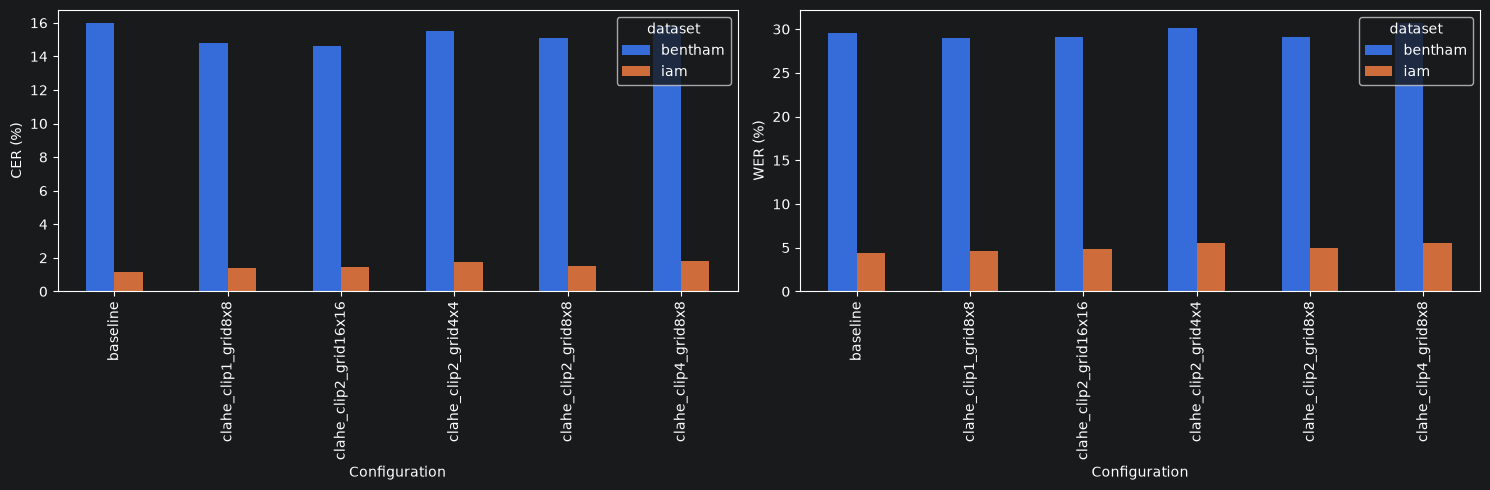

{
  "best_overall": "clahe_clip2_grid16x16",
  "best_clahe": "clahe_clip2_grid16x16",
  "clahe_parameters": {
    "name": "clahe",
    "enabled": true,
    "clip_limit": 2,
    "tile_grid_size": [
      16,
      16
    ],
    "processing": "grayscale directly; RGB via LAB luminance"
  },
  "criterion": "lowest equal-dataset mean corpus CER; WER tie-breaker; baseline eligible",
  "dataset_winners": [
    {
      "dataset": "bentham",
      "configuration": "clahe_clip2_grid16x16",
      "cer": 0.1463359639233371,
      "wer": 0.29106945975744214
    },
    {
      "dataset": "iam",
      "configuration": "baseline",
      "cer": 0.011541072640868975,
      "wer": 0.0438034188034188
    }
  ]
}
Subset validation optimum; confirm on validation data before freezing final test parameters.


In [4]:
import matplotlib.pyplot as plt
assert len(table) == 12 and table.sample_count.eq(100).all()
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, metric in zip(axes, ['cer', 'wer']):
    table.pivot(index='configuration', columns='dataset', values=metric).mul(100).plot.bar(ax=ax)
    ax.set_ylabel(metric.upper() + ' (%)')
    ax.set_xlabel('Configuration')
fig.tight_layout()
fig.savefig(OUTPUT / 'corpus_error_rates.png', dpi=160, bbox_inches='tight')
plt.show()
best_clahe = ranking.drop(index='baseline').index[0]
selection = {'best_overall': ranking.index[0], 'best_clahe': best_clahe,
    'clahe_parameters': configs[best_clahe].to_config(),
    'criterion': metadata['selection'],
    'dataset_winners': winners[['dataset', 'configuration', 'cer', 'wer']].to_dict('records')}
(OUTPUT / 'selection.json').write_text(json.dumps(selection, indent=2))
(OUTPUT / 'status.json').write_text(json.dumps({'status': 'complete', 'clahe_configurations': 5,
    'baseline_configurations': 1, 'validation_samples_per_dataset': 100,
    'completed_dataset_configuration_pairs': 12, 'seed': SEED}, indent=2))
print(json.dumps(selection, indent=2))
print('Subset validation optimum; confirm on validation data before freezing final test parameters.')